# 06. RAG: embedding, indice di ricerca e valutazione
**Progetto:** HelpDesk AI · **Passo 3:** Generative AI

## Obiettivo di questo notebook
Nel notebook 05 abbiamo preparato 3.065 chunk, ora costruiamo la ricerca: data una richiesta dell'utente, trovare i chunk che contengono la risposta.

La ricerca è **semantica**: non cerca le stesse parole, ma lo stesso **significato**. Per farlo trasforma ogni testo in un **embedding**, un vettore di numeri costruito in modo che testi con significato simile abbiano vettori vicini. 

```
chunk -> embeddings (OpenAI) -> indice (ChromaDB)
richiesta -> embedding -> i 5 chunk più vicini nell'indice
```
Poi valutiamo se:
- aggiungere **titolo e dispositivo** al testo dei chunk aiuta la ricerca?
- serve **tradurre** la richiesta in inglese, o funziona anche in italiano?
- quanto aiutano i **filtri** per categoria (dal classificatore) e per dispositivo (chiesto all'utente)?

## Cosa faremo

1. Import e configurazione
2. Caricamento dei chunk
3. Il testo da trasformare in embeddings
4. Embeddings con OpenAI
5. L'indice di ricerca (ChromaDB)
6. Le richieste di prova
7. Il classificatore sulle richieste di prova
8. Valutazione della ricerca
9. Analisi dei risultati
10. Scelta della configurazione e salvataggio
11. Riepilogo

## 1. Import e configurazione

| Libreria | A cosa serve |
|---|---|
| `openai` | creare gli embeddings con il modello di OpenAI |
| `chromadb` | salvare gli embeddings in un indice su disco e cercare i più vicini |
| `dotenv` | leggere la chiave API dal file `.env`, senza scriverla nel codice |
| `joblib` | caricare il classificatore del notebook 03-04 |

**Perché `text-embedding-3-small`?** È il modello di embeddings più economico di OpenAI e funziona con molte lingue, compreso l'italiano. Alternative: `text-embedding-3-large` è più preciso ma costa circa 6 volte di più. Un modello locale (`sentence-transformers`) è gratuito ma rende più pesante l'app da pubblicare.

**Perché ChromaDB?** È un database vettoriale che gira dentro Python, salva l'indice in una cartella e permette di filtrare per metadati (categoria, dispositivo).

In [1]:
from pathlib import Path
import os
import json
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import chromadb
from dotenv import load_dotenv
from openai import OpenAI

In [2]:
# --- Percorsi ---
PROJECT_DIR = Path("..")
KB_DIR = PROJECT_DIR / "knowledge_base"
CHUNKS_PATH = KB_DIR / "chunks.jsonl"
RICHIESTE_PATH = KB_DIR / "richieste_prova.csv"
CHROMA_DIR = KB_DIR / "chroma"                    # indice di ricerca (escluso da GitHub)
MODELS_DIR = PROJECT_DIR / "models"
CONFIG_RAG_PATH = MODELS_DIR / "configurazione_rag.json"
EMBEDDINGS_RICHIESTE_PATH = KB_DIR / "embeddings_richieste.npz"   # embeddings delle richieste di prova (escluso da GitHub)

# --- Embeddings e ricerca ---
MODELLO_EMBEDDINGS = "text-embedding-3-small"
PREZZO_PER_MILIONE = 0.02      # dollari per milione di token (novembre 2026)
DIMENSIONE_LOTTO = 200         # testi inviati in ogni chiamata all'API
K = 5                          # quanti chunk restituisce la ricerca
RICREA_INDICE = False          # True per ricreare l'indice da zero (si paga di nuovo)

# --- Stile dei grafici ---
COLORE = "#2a78d6"
TESTO_SECONDARIO = "#52514e"
GRIGLIA = "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIGLIA,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRIGLIA,
    "xtick.color": TESTO_SECONDARIO,
    "ytick.color": TESTO_SECONDARIO,
})
pd.set_option("display.max_colwidth", 120)

### Chiave API

`load_dotenv` legge il file `.env` e mette la chiave tra le variabili d'ambiente; `OpenAI()` la prende da lì da solo.

In [3]:
load_dotenv(PROJECT_DIR / ".env")
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError("Chiave non trovata: crea il file .env nella cartella del progetto con OPENAI_API_KEY=...")

client = OpenAI()
print("Chiave caricata.")

Chiave caricata.


## 2. Caricamento dei chunk

Leggiamo `chunks.jsonl` del notebook 05. Aggiungiamo un campo **`dispositivo`**: per i manuali è la periferica, per gli articoli Microsoft è `"computer"`. Così ogni chunk ha un dispositivo, e potremo filtrare anche le richieste sul computer.

In [4]:
with open(CHUNKS_PATH, encoding="utf-8") as f:
    chunk = pd.DataFrame([json.loads(riga) for riga in f])

chunk["dispositivo"] = chunk["periferica"].replace("", "computer")
print(f"Chunk caricati: {len(chunk)}")
display(chunk["dispositivo"].value_counts().to_frame("chunk"))

Chunk caricati: 3065


,chunk
dispositivo,
stampante di rete,2083
stampante di etichette,501
computer,250
monitor,66
POS,59
selezionatrice di banconote,52
stampante di sportello,32
pad di firma,22


## 3. Il testo da trasformare in embeddings

Nel notebook 05 (parte 8) abbiamo visto che molti chunk non dicono di quale dispositivo parlano: "Open door A and remove the jammed paper" potrebbe riferirsi a qualsiasi stampante. Se l'embedding non contiene questa informazione la ricerca non può usarla.

Prepariamo quindi due versioni del testo per confrontarle:

- **semplice:** solo il testo del chunk;
- **con intestazione:** prima del testo, tre righe con editore e titolo del documento, dispositivo e sezione.

Il dispositivo nell'intestazione è scritto in inglese e con parole descrittive ("counter passbook printer") perché i chunk sono quasi tutti in inglese e le richieste tradotte useranno quelle parole.

Il testo salvato nell'indice, quello che leggerà l'LLM, resta il chunk originale: l'intestazione serve solo a costruire l'embedding.

In [5]:
DISPOSITIVO_IN_INGLESE = {
    "computer": "Windows computer",
    "POS": "POS payment terminal (card reader)",
    "pad di firma": "electronic signature pad",
    "stampante di sportello": "counter passbook and document printer",
    "stampante di rete": "network multifunction printer",
    "stampante di etichette": "label printer",
    "monitor": "computer monitor (display)",
    "selezionatrice di banconote": "banknote counter (currency scanner)",
}
assert set(chunk["dispositivo"]) <= set(DISPOSITIVO_IN_INGLESE), "Dispositivo senza traduzione"


def intestazione(c):
    righe = [f"{c['editore']} - {c['titolo']}", f"Device: {DISPOSITIVO_IN_INGLESE[c['dispositivo']]}"]
    if c["sezione"]:
        righe.append(f"Section: {c['sezione']}")
    return "\n".join(righe)


chunk["testo_semplice"] = chunk["testo"]
chunk["testo_intestazione"] = chunk.apply(intestazione, axis=1) + "\n\n" + chunk["testo"]

# Due esempi: il primo chunk di un manuale e il primo di un articolo Microsoft
for testo in [chunk.loc[chunk["dispositivo"] != "computer", "testo_intestazione"].iloc[0],
              chunk.loc[chunk["dispositivo"] == "computer", "testo_intestazione"].iloc[0]]:
    print(testo[:350], "...\n")

Epson - WF-M5899 User's Guide
Device: network multifunction printer

WF-M5899 User's Guide
Welcome to the WF-M5899 User's Guide.
For a printable PDF copy of this guide, click here.
Note: Availability of products in this guide varies by country. ...

Microsoft - Can't use Azure Multi-Factor Authentication to sign in to cloud services after you lose your phone or the phone number changes
Device: Windows computer
Section: Can't use Azure Multi-Factor Authentication to sign in to cloud services after you lose your phone or the phone number changes

Original product version: Cloud Services (Web rol ...



## 4. Embeddings con OpenAI

Mandiamo i testi all'API in lotti da 200: una chiamata per ogni testo sarebbe lenta mentre una sola chiamata con tutto supererebbe i limiti dell'API.

Per passare a un altro fornitore o a un modello locale basterebbe riscrivere questa funzione.

Prima di spendere stimiamo il costo: in inglese un token vale in media circa 4 caratteri.

In [6]:
def crea_embeddings(testi, dimensione_lotto=DIMENSIONE_LOTTO):
    # Restituisce (matrice degli embeddings, token usati). Unico punto che dipende dal fornitore.
    vettori, token = [], 0
    for inizio in range(0, len(testi), dimensione_lotto):
        risposta = client.embeddings.create(model=MODELLO_EMBEDDINGS, input=testi[inizio:inizio + dimensione_lotto])
        vettori.extend(dato.embedding for dato in risposta.data)
        token += risposta.usage.total_tokens
    return np.array(vettori, dtype=np.float32), token


caratteri = chunk["testo_semplice"].str.len().sum() + chunk["testo_intestazione"].str.len().sum()
token_stimati = caratteri / 4
print(f"Token stimati per le due versioni: {token_stimati / 1e6:.2f} milioni "
      f"-> circa {token_stimati / 1e6 * PREZZO_PER_MILIONE:.3f} dollari")

Token stimati per le due versioni: 1.13 milioni -> circa 0.023 dollari


## 5. L'indice di ricerca (ChromaDB)
In ChromaDB una collezione è un contenitore con un nome, simile a una tabella di un database: ogni elemento ha un identificativo, un embedding, un testo e dei metadati.
Creiamo due collezioni (una per ogni versione del testo) in una cartella su disco, `knowledge_base/chroma`. Per ogni chunk salviamo:

| Cosa | A cosa serve |
|---|---|
| `id` | l'identificativo del chunk (`zebra_zd421-0059`) |
| `embedding` | il vettore su cui si fa la ricerca |
| `document` | il testo originale del chunk da passare all'LLM |
| `metadata` | fonte, titolo, editore, categoria, dispositivo, link, pagina, sezione: per filtrare e per citare |

**Distanza del coseno:** misura quanto due vettori puntano nella stessa direzione (0 = stesso significato, valori più alti = più sono diversi). È la misura consigliata per gli embeddings di OpenAI.

Se la collezione esiste già con tutti i chunk la riusiamo. ChromaDB salva l'indice su disco e rieseguire il notebook non costa nulla. Per ricrearlo da zero basta modificare `RICREA_INDICE = True` nella sezione 1 di questo notebook.

ChromaDB non accetta valori mancanti nei metadati: per gli articoli Microsoft, che non hanno pagine, scriviamo `pagina = 0`.

In [7]:
chroma = chromadb.PersistentClient(path=str(CHROMA_DIR))


def metadati(c):
    return {
        "id_fonte": c["id_fonte"], "titolo": c["titolo"], "editore": c["editore"],
        "categoria": c["categoria"], "dispositivo": c["dispositivo"], "lingua": c["lingua"],
        "url": c["url"], "pagina": int(c["pagina"]) if pd.notna(c["pagina"]) else 0, "sezione": c["sezione"],
    }


def costruisci_collezione(nome, colonna_testo):
    nomi_esistenti = [c.name if hasattr(c, "name") else c for c in chroma.list_collections()]
    if nome in nomi_esistenti:
        collezione = chroma.get_collection(nome)
        if collezione.count() == len(chunk) and not RICREA_INDICE:
            print(f"{nome}: già pronta ({collezione.count()} chunk), nessuna spesa")
            return collezione
        chroma.delete_collection(nome)        # incompleta o da ricreare: si riparte da zero

    collezione = chroma.create_collection(nome, metadata={"hnsw:space": "cosine"}, embedding_function=None)
    inizio = time.perf_counter()
    vettori, token = crea_embeddings(chunk[colonna_testo].tolist())
    lista_metadati = [metadati(c) for c in chunk.to_dict("records")]
    for i in range(0, len(chunk), 1000):          # ChromaDB accetta lotti di dimensione limitata
        collezione.add(
            ids=chunk["id_chunk"].iloc[i:i + 1000].tolist(),
            embeddings=vettori[i:i + 1000],
            documents=chunk["testo"].iloc[i:i + 1000].tolist(),
            metadatas=lista_metadati[i:i + 1000],
        )
    print(f"{nome}: {collezione.count()} chunk | {token:,} token | circa {token / 1e6 * PREZZO_PER_MILIONE:.3f} dollari "
          f"| {time.perf_counter() - inizio:.0f} secondi")
    return collezione

In [8]:
%%time
collezione_semplice = costruisci_collezione("kb_semplice", "testo_semplice")
collezione_intestazione = costruisci_collezione("kb_intestazione", "testo_intestazione")

kb_semplice: già pronta (3065 chunk), nessuna spesa
kb_intestazione: già pronta (3065 chunk), nessuna spesa
CPU times: total: 141 ms
Wall time: 63 ms


### Controllo dell'indice

Una ricerca su ogni collezione, con e senza filtro, usando l'embedding di un chunk già salvato (nessuna spesa). ChromaDB lavora bene con un solo processo per cartella: se due notebook aprono lo stesso indice insieme, l'indice si può rovinare restituendo l'errore "Error finding id".

In [9]:
# Controllo dell'indice: una ricerca su ogni collezione, con e senza filtro.
# Usiamo l'embedding di un chunk già salvato, quindi non spendiamo nulla.
for collezione in [collezione_semplice, collezione_intestazione]:
    vettore = collezione.get(limit=1, include=["embeddings"])["embeddings"][0]
    for filtro in [None, {"dispositivo": "stampante di rete"}, {"categoria": "Access"}]:
        risultato = collezione.query(query_embeddings=[vettore], n_results=K, where=filtro)
        print(f"{collezione.name:16} filtro={filtro}: {len(risultato['ids'][0])} risultati")
print(f"ChromaDB versione {chromadb.__version__}: indice a posto")

kb_semplice      filtro=None: 5 risultati
kb_semplice      filtro={'dispositivo': 'stampante di rete'}: 5 risultati
kb_semplice      filtro={'categoria': 'Access'}: 5 risultati
kb_intestazione  filtro=None: 5 risultati
kb_intestazione  filtro={'dispositivo': 'stampante di rete'}: 5 risultati
kb_intestazione  filtro={'categoria': 'Access'}: 5 risultati
ChromaDB versione 1.5.9: indice a posto


### Osservazioni (parte 5)
- Indicizzati **3.065 chunk** in due collezioni: **1.060.571 token** in tutto (496.215 per il testo semplice, 564.356 con l'intestazione), per un costo di circa **0,02 dollari**.
- L'intestazione aggiunge in media **22 token per chunk** (+14%): da 162 a 184 token.
- La stima con 4 caratteri per token era leggermente alta: con chunk di 695 caratteri in media e 162 token, ogni token vale circa 4,3 caratteri. È comunque una buona stima per decidere prima di spendere.
- Rieseguendo la cella le collezioni vengono riusate ("già pronta, nessuna spesa"): l'indice è salvato su disco in `knowledge_base/chroma` e anche l'app lo aprirà senza ricalcolare gli embeddings.

## 6. Richieste di prova

Per misurare la ricerca servono richieste di cui sappiamo già la risposta giusta. Il file `knowledge_base/richieste_prova.csv` ne contiene 36, scritte come le scriverebbe un utente a sportello:

| Colonna | Significato |
|---|---|
| `richiesta_it` | la richiesta in italiano con parole quotidiane |
| `richiesta_en` | la traduzione in inglese fatta a mano: nell'app la farà l'LLM |
| `categoria_attesa` | la categoria giusta per il classificatore |
| `dispositivo_atteso` | il dispositivo di cui si parla |
| `fonti_attese` | i documenti che contengono la risposta (uno o più, separati da `|`) |

**Perché giudichiamo la fonte e non il singolo chunk?** Indicare a mano il chunk esatto per 36 richieste sarebbe lungo e cambierebbe a ogni modifica della divisione in chunk. Chiediamo una cosa più semplice ma già utile: tra i primi 5 risultati c'è **almeno un chunk del documento giusto**?

**Attenzione:** 36 richieste sono poche. Ogni richiesta vale 2,8 punti percentuali (1 su 36), quindi una differenza di 1-2 richieste tra due configurazioni può dipendere da come è scritta una singola frase e non è affidabile. Considereremo significative solo differenze più ampie, o che vanno nella stessa direzione su tutte le misure.

**Embeddings delle richieste salvati su file.** Ricostruendo l'indice e ricalcolando gli embeddings, due richieste al confine (R04 e R07) hanno cambiato esito: l'API può restituire vettori leggermente diversi per lo stesso testo e, quando due chunk sono quasi alla stessa distanza, basta una differenza minima per scambiarli. L'indice resta su disco; per rendere ripetibile anche il resto, calcoliamo gli embeddings delle richieste una volta sola e li salviamo insieme ai testi. Se una richiesta cambia, il notebook li ricalcola.

In [10]:
richieste = pd.read_csv(RICHIESTE_PATH)
richieste["fonti_attese"] = richieste["fonti_attese"].str.split("|")
print(f"Richieste di prova: {len(richieste)}")
display(pd.crosstab(richieste["dispositivo_atteso"], richieste["categoria_attesa"], margins=True, margins_name="totale"))
display(richieste[["id", "richiesta_it", "richiesta_en"]].head(5))

# Embeddings delle richieste: calcolati una volta e salvati, così ogni esecuzione dà gli stessi risultati
def embeddings_richieste():
    testi_it = richieste["richiesta_it"].tolist()
    testi_en = richieste["richiesta_en"].tolist()
    if EMBEDDINGS_RICHIESTE_PATH.exists():
        with np.load(EMBEDDINGS_RICHIESTE_PATH) as salvati:
            if salvati["testi_it"].tolist() == testi_it and salvati["testi_en"].tolist() == testi_en:
                print("Embeddings delle richieste letti da file: nessuna spesa, stessi vettori delle esecuzioni precedenti")
                return salvati["it"], salvati["en"]
    vettori_it, _ = crea_embeddings(testi_it)
    vettori_en, _ = crea_embeddings(testi_en)
    np.savez(EMBEDDINGS_RICHIESTE_PATH, testi_it=testi_it, testi_en=testi_en, it=vettori_it, en=vettori_en)
    print(f"Embeddings delle richieste calcolati e salvati in {EMBEDDINGS_RICHIESTE_PATH.name}")
    return vettori_it, vettori_en


vettori_it, vettori_en = embeddings_richieste()

Richieste di prova: 36


categoria_attesa,Access,Administrative rights,Hardware,Storage,totale
dispositivo_atteso,,,,,
POS,0,0,3,0,3
computer,5,3,4,4,16
monitor,0,0,2,0,2
pad di firma,0,0,3,0,3
selezionatrice di banconote,0,0,2,0,2
stampante di etichette,0,0,2,0,2
stampante di rete,0,0,5,0,5
stampante di sportello,0,0,3,0,3
totale,5,3,24,4,36


,id,richiesta_it,richiesta_en
0,R01,La stampante non acquisisce automaticamente i dati dai fogli scansionati,The printer doesn't automatically capture the data from the scanned sheets
1,R02,Si è incastrato un foglio dentro la stampante di sportello,A sheet got stuck inside the counter printer
2,R03,La stampa sui libretti è sbiadita e non si legge quasi più,The printing on the passbooks is faded and barely readable anymore
3,R04,"Il POS non è collegato, dà errore di connessione","The POS is not connected, it gives a connection error"
4,R05,"Il POS non stampa lo scontrino, esce il foglio bianco","The POS doesn't print the receipt, the paper comes out blank"


Embeddings delle richieste letti da file: nessuna spesa, stessi vettori delle esecuzioni precedenti


### Osservazioni (parte 6)
- **36 richieste di prova**: 24 di categoria Hardware, che coprono tutti gli 8 tipi di dispositivo, e 12 sul computer per Access (5), Storage (4) e Administrative rights (3).
- Sono scritte immaginando come le scriverebbe un utente allo sportello, alcune sono volutamente vaghe ("la stampante", "il pad", "il wifi"): misurano la ricerca in condizioni realistiche non ideali.
- Mancano di proposito HR Support, Purchase, Internal Project e Miscellaneous: per quelle categorie il chatbot inoltra il ticket senza cercare nella knowledge base.
- Le traduzioni in inglese sono fatte a mano e fedeli al testo italiano; nell'app le farà l'LLM.
- Con 36 richieste ogni richiesta vale 2,8 punti percentuali: differenze di 1-2 richieste non sono affidabili.

## 7. Il classificatore sulle richieste di prova

Uno dei filtri che vogliamo provare è la **categoria prevista dal classificatore**. Usiamo il modello finale del notebook 04 così come farà l'app:

1. la richiesta in inglese (il classificatore è stato addestrato su ticket in inglese);
2. preparata come i ticket del dataset: minuscolo, solo lettere, spazi singoli;
3. il filtro si applica solo se la sicurezza è sopra la soglia scelta nel notebook 04. Sotto la soglia l'app chiederà dettagli: qui, per la ricerca, non filtriamo.

È anche un primo test del classificatore su testi molto diversi da quelli di addestramento: frasi brevi scritte da chi lavora allo sportello invece di email complete.

In [11]:
with open(MODELS_DIR / "configurazione_modello.json", encoding="utf-8") as f:
    configurazione_classificatore = json.load(f)
assert configurazione_classificatore["modello_finale"] == "SVM", "Questo notebook usa il classificatore salvato con joblib"
classificatore = joblib.load(MODELS_DIR / configurazione_classificatore["file_modello"])
SOGLIA = configurazione_classificatore["soglia_sicurezza"]


def prepara_per_classificatore(testo):
    # Come i ticket del dataset: minuscolo, solo lettere, spazi singoli
    return re.sub(r"\s+", " ", re.sub(r"[^a-z\s]", " ", testo.lower())).strip()


probabilita = classificatore.predict_proba(richieste["richiesta_en"].map(prepara_per_classificatore))
richieste["categoria_prevista"] = classificatore.classes_[probabilita.argmax(axis=1)]
richieste["sicurezza"] = probabilita.max(axis=1).round(2)
richieste["sopra_soglia"] = richieste["sicurezza"] >= SOGLIA
corretta = richieste["categoria_prevista"] == richieste["categoria_attesa"]

print(f"Soglia di sicurezza: {SOGLIA}")
print(f"Categoria corretta: {corretta.sum()} su {len(richieste)} | sopra la soglia: {richieste['sopra_soglia'].sum()} "
      f"(di cui corrette: {(corretta & richieste['sopra_soglia']).sum()})")
display(pd.crosstab(richieste["categoria_attesa"], richieste["categoria_prevista"]))

Soglia di sicurezza: 0.55
Categoria corretta: 19 su 36 | sopra la soglia: 25 (di cui corrette: 14)


categoria_prevista,Access,Administrative rights,HR Support,Hardware,Miscellaneous,Storage
categoria_attesa,,,,,,
Access,2,1,0,2,0,0
Administrative rights,0,1,1,0,1,0
Hardware,2,0,3,14,4,1
Storage,0,0,0,2,0,2


In [12]:
# Le richieste classificate male
display(richieste.loc[~corretta, ["id", "richiesta_en", "categoria_attesa", "categoria_prevista", "sicurezza"]])

,id,richiesta_en,categoria_attesa,categoria_prevista,sicurezza
0,R01,The printer doesn't automatically capture the data from the scanned sheets,Hardware,Miscellaneous,0.49
1,R02,A sheet got stuck inside the counter printer,Hardware,HR Support,0.73
4,R05,"The POS doesn't print the receipt, the paper comes out blank",Hardware,Miscellaneous,0.32
5,R06,The customer inserts the card but the POS doesn't read it,Hardware,Access,0.89
7,R08,The customer signs on the pad but the signature doesn't appear,Hardware,Miscellaneous,0.34
15,R16,The Kyocera multifunction printer has a paper jam,Hardware,HR Support,0.51
17,R18,The Lexmark printer says to change the toner but I just changed it,Hardware,Miscellaneous,0.92
19,R20,I can't scan to a folder from the multifunction printer,Hardware,Storage,0.92
21,R22,The VPN gives an error when I connect,Hardware,HR Support,0.53
23,R24,The smart card reader doesn't work anymore,Hardware,Access,0.92


### Osservazioni (parte 7)
- Sulle richieste di prova il classificatore indovina la categoria **19 volte su 36 (53%)**, contro l'86% sul test del notebook 04. Sopra la soglia di 0,55 ci sono 25 richieste, ma solo **14 sono corrette (56%)**: la soglia scelta sui ticket del dataset non funziona su questi testi.
- La causa potrebbe essere il cambio di distribuzione (*domain shift*). Il modello ha imparato le parole tipiche dei ticket email di un'azienda e le nostre richieste usano le stesse parole con un altro significato: *card* (badge nel dataset) porta ad Access la carta di pagamento e la smart card (R06, R24); *folder* porta a Storage la scansione su cartella (R20); *change* porta a Miscellaneous il cambio del toner (R18); *error* porta a HR Support un errore di installazione (R36).
- **9 errori su 17 finiscono in HR Support o Miscellaneous** che sono categorie senza documenti: il chatbot inoltrerebbe il ticket senza proporre istruzioni.
- Non modifico soglia né modello usando queste richieste che servono a valutare la ricerca. Nel notebook 07 confronterò il classificatore con la classificazione fatta dall'LLM sulle stesse richieste.

## 8. Valutazione della ricerca

### Le misure

Per ogni richiesta cerchiamo i 5 chunk più vicini e guardiamo da quali documenti vengono:

| Misura | Domanda a cui risponde |
|---|---|
| **trovata nei primi 5** (*hit rate*) | almeno uno dei 5 chunk viene da un documento giusto? È la misura principale: se il documento giusto non arriva all'LLM, la risposta non può essere giusta |
| **MRR** (*Mean Reciprocal Rank*) | quanto in alto compare il primo chunk giusto? Vale 1 se è il primo, 1/2 se è il secondo, ... 0 se non c'è. È la media di questi valori |
| **precisione nei primi 5** | quanti dei 5 chunk vengono da documenti giusti? Più è alta meno testo inutile riceve l'LLM |

### Le configurazioni

Variamo una cosa alla volta:

| Configurazione | Testo indicizzato | Richiesta | Filtro |
|---|---|---|---|
| A | semplice | italiano | nessuno |
| B | semplice | inglese | nessuno |
| C | con intestazione | italiano | nessuno |
| D | con intestazione | inglese | nessuno |
| E | con intestazione | inglese | categoria prevista dal classificatore, se sopra la soglia |
| F | con intestazione | inglese | dispositivo (nell'app: riconosciuto dal testo o chiesto all'utente) |

A contro B e C contro D misurano l'effetto della **lingua**; A contro C e B contro D quello dell'**intestazione**; D contro E e F quello dei **filtri**.

**Nota sul filtro per categoria (E):** se il classificatore prevede una categoria senza documenti (es. HR Support) con sicurezza alta, la ricerca non trova nulla. È corretto contarlo come errore: nell'app quel ticket verrebbe inoltrato senza istruzioni.

In [13]:
def cerca(collezione, vettore, k=K, filtro=None):
    # Restituisce i metadati e le distanze dei k chunk più vicini (eventualmente filtrati)
    risultato = collezione.query(query_embeddings=[vettore.tolist()], n_results=k, where=filtro, include=["metadatas", "distances"])
    return risultato["metadatas"][0], risultato["distances"][0]


def valuta(fonti_trovate, fonti_attese):
    giuste = [fonte in fonti_attese for fonte in fonti_trovate]
    posizione = giuste.index(True) + 1 if any(giuste) else None
    return {
        "trovata": posizione is not None,
        "reciprocal_rank": 1 / posizione if posizione else 0.0,
        "precisione": sum(giuste) / len(giuste) if giuste else 0.0,
    }


def filtro_categoria(r):
    return {"categoria": r["categoria_prevista"]} if r["sopra_soglia"] else None


def filtro_dispositivo(r):
    return {"dispositivo": r["dispositivo_atteso"]}


configurazioni = {
    "A. semplice · italiano": (collezione_semplice, "it", None),
    "B. semplice · inglese": (collezione_semplice, "en", None),
    "C. intestazione · italiano": (collezione_intestazione, "it", None),
    "D. intestazione · inglese": (collezione_intestazione, "en", None),
    "E. D + filtro categoria": (collezione_intestazione, "en", filtro_categoria),
    "F. D + filtro dispositivo": (collezione_intestazione, "en", filtro_dispositivo),
}

In [14]:
%%time
dettaglio = []
for nome, (collezione, lingua, crea_filtro) in configurazioni.items():
    vettori = vettori_it if lingua == "it" else vettori_en
    for i, r in enumerate(richieste.to_dict("records")):
        trovati, distanze = cerca(collezione, vettori[i], filtro=crea_filtro(r) if crea_filtro else None)
        fonti_trovate = [m["id_fonte"] for m in trovati]
        dettaglio.append({"configurazione": nome, "id": r["id"], "dispositivo": r["dispositivo_atteso"],
                          **valuta(fonti_trovate, r["fonti_attese"]),
                          "prima_fonte": fonti_trovate[0] if fonti_trovate else "(nessun risultato)"})
dettaglio = pd.DataFrame(dettaglio)

risultati = dettaglio.groupby("configurazione").agg(
    trovata_nei_primi_5=("trovata", "mean"),
    MRR=("reciprocal_rank", "mean"),
    precisione_nei_primi_5=("precisione", "mean"),
)
risultati["trovata_nei_primi_5"] = (risultati["trovata_nei_primi_5"] * 100).round(1)
risultati["precisione_nei_primi_5"] = (risultati["precisione_nei_primi_5"] * 100).round(1)
risultati["MRR"] = risultati["MRR"].round(3)
display(risultati.rename(columns={"trovata_nei_primi_5": "trovata nei primi 5 (%)",
                                  "precisione_nei_primi_5": "precisione nei primi 5 (%)"}))

,trovata nei primi 5 (%),MRR,precisione nei primi 5 (%)
configurazione,,,
A. semplice · italiano,61.1,0.529,37.8
B. semplice · inglese,86.1,0.771,57.8
C. intestazione · italiano,75.0,0.660,60.0
D. intestazione · inglese,94.4,0.944,81.7
E. D + filtro categoria,63.9,0.639,53.9
F. D + filtro dispositivo,100.0,1.000,94.4


CPU times: total: 641 ms
Wall time: 570 ms


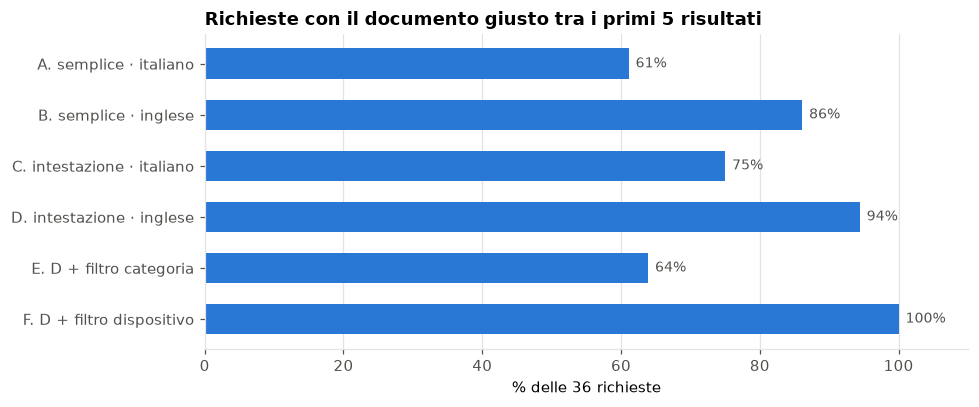

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ordinati = risultati.sort_index(ascending=False)
ax.barh(ordinati.index, ordinati["trovata_nei_primi_5"], color=COLORE, height=0.6)
for posizione, valore in enumerate(ordinati["trovata_nei_primi_5"]):
    ax.text(valore + 1, posizione, f"{valore:.0f}%", va="center", fontsize=9, color=TESTO_SECONDARIO)
ax.set_xlim(0, 110)
ax.set_title("Richieste con il documento giusto tra i primi 5 risultati")
ax.set_xlabel("% delle 36 richieste")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Osservazioni (parte 8)

| Configurazione | Richieste trovate | MRR | Precisione |
|---|---|---|---|
| A. semplice · italiano | 22/36 | 0,53 | 38% |
| B. semplice · inglese | 31/36 | 0,77 | 58% |
| C. intestazione · italiano | 27/36 | 0,66 | 60% |
| D. intestazione · inglese | 34/36 | 0,94 | 82% |
| E. D + filtro categoria | 23/36 | 0,64 | 54% |
| F. D + filtro dispositivo | 36/36 | 1,00 | 94% |

- **Lingua:** tradurre la richiesta in inglese è l'intervento che migliora maggiormente: +9 richieste senza intestazione (A->B), +7 con intestazione (C->D). I documenti sono quasi tutti in inglese: il modello di embedding è multilingue ma cerca più facilmente testi nella sua stessa lingua.
- **Intestazione:** aiuta in entrambe le lingue ma meno della traduzione: +5 richieste in italiano (A->C), +3 in inglese (B->D). Alza molto la precisione (+22 punti in italiano, +24 in inglese) perché un chunk breve spesso non dice di quale dispositivo parla, mentre l'intestazione sì. C'è anche un'altra causa: i chunk dello stesso documento condividono l'intestazione, quindi i 5 risultati tendono a venire dallo stesso documento. Se il documento è giusto l'LLM riceve più passaggi coerenti; se è sbagliato, sono sbagliati tutti e 5.
- **Insieme** i due interventi portano da 22 a 34 richieste trovate. In D l'MRR (0,944) coincide con la percentuale trovata: quando il documento giusto compare è sempre al primo posto. Le 2 richieste mancate sono errori completi.
- **Filtro per categoria (E): peggiora**, da 34 a 23 richieste: 11 in meno, tante quante le richieste che il classificatore sbaglia sopra la soglia. Ogni errore fatto con sicurezza alta esclude il documento giusto e, per HR Support e Miscellaneous, non esiste nessun documento. Il filtro trasforma gli errori del classificatore in errori della ricerca. Un filtro è utile solo se è più affidabile della ricerca che restringe: sopra la soglia il classificatore è giusto nel 56% dei casi, la ricerca senza filtri nel 94%.
- **Filtro per dispositivo (F):** 36 su 36, sempre al primo posto, con il 94% dei chunk dal documento giusto. Due precisazioni da fare:
  1. usa il dispositivo **atteso**, cioè la risposta giusta. Nell'app arriverà dal clic dell'utente o dal riconoscimento nel testo, che può sbagliare: questo è quindi il risultato *con il dispositivo giusto*;
  2. per quattro dispositivi (stampante di sportello, stampante di etichette, monitor, selezionatrice di banconote) c'è un solo manuale, quindi 9 richieste su 36 trovano per forza il documento giusto.

Il test vero per F sono le 16 richieste sul computer (27 articoli Microsoft) e la verifica dei chunk della sezione 9.4.

## 9. Analisi dei risultati

### 9.1 Per dispositivo

Dal notebook 05 avevamo compreso che quattro manuali di stampanti sono l'84% della knowledge base. Vediamo per quali dispositivi la ricerca senza filtri (D) sbaglia di più, e quanto recupera il filtro per dispositivo (F).

In [16]:
per_dispositivo = (dettaglio[dettaglio["configurazione"].isin(["D. intestazione · inglese", "F. D + filtro dispositivo"])]
                   .pivot_table(index="dispositivo", columns="configurazione", values="trovata", aggfunc="mean")
                   .mul(100).round(0))
per_dispositivo.insert(0, "richieste", richieste["dispositivo_atteso"].value_counts())
display(per_dispositivo.sort_values("D. intestazione · inglese"))

configurazione,richieste,D. intestazione · inglese,F. D + filtro dispositivo
dispositivo,,,
POS,3,67.0,100.0
stampante di sportello,3,67.0,100.0
monitor,2,100.0,100.0
computer,16,100.0,100.0
pad di firma,3,100.0,100.0
selezionatrice di banconote,2,100.0,100.0
stampante di etichette,2,100.0,100.0
stampante di rete,5,100.0,100.0


### 9.2 Dove la ricerca sbaglia

Configurazione senza filtri (D): quale documento compare al primo posto quando la ricerca sbaglia? Se sono sempre i manuali delle stampanti è il "dominio" previsto nel notebook 05.

In [17]:
errori = dettaglio[(dettaglio["configurazione"] == "D. intestazione · inglese") & ~dettaglio["trovata"]]
errori = errori.merge(richieste[["id", "richiesta_it", "fonti_attese"]], on="id")
display(errori[["id", "richiesta_it", "fonti_attese", "prima_fonte"]])

ancora_errate = dettaglio[(dettaglio["configurazione"] == "F. D + filtro dispositivo") & ~dettaglio["trovata"]]
print(f"Con il filtro per dispositivo restano senza documento giusto: {len(ancora_errate)} richieste "
      f"({', '.join(ancora_errate['id']) or 'nessuna'})")

,id,richiesta_it,fonti_attese,prima_fonte
0,R01,La stampante non acquisisce automaticamente i dati dai fogli scansionati,[olivetti_mb2],epson_wfm5899
1,R04,"Il POS non è collegato, dà errore di connessione","[nexi_pos_ingenico_it, ingenico_ipp320, pax_a920_it]",ms_wireless-network-connectivity-issues-troubleshooting


Con il filtro per dispositivo restano senza documento giusto: 0 richieste (nessuna)


### 9.3 Esempio completo

Ecco cosa arriverà all'LLM per una richiesta: i 5 chunk trovati contenenti fonte, pagina o sezione e distanza. La distanza ci servirà anche nell'app: se anche il chunk più vicino è lontano, la knowledge base probabilmente non contiene la risposta e il chatbot dovrebbe dirlo invece di inventare.

In [18]:
def mostra_risultati(id_richiesta, collezione=collezione_intestazione, con_filtro=True):
    r = richieste.set_index("id").loc[id_richiesta]
    filtro = {"dispositivo": r["dispositivo_atteso"]} if con_filtro else None
    i = richieste.index[richieste["id"] == id_richiesta][0]
    risultato = collezione.query(query_embeddings=[vettori_en[i].tolist()], n_results=K, where=filtro,
                                 include=["metadatas", "distances", "documents"])
    print(f"Richiesta: {r['richiesta_it']}\nIn inglese: {r['richiesta_en']}\nFiltro: {filtro}\n")
    for m, d, testo in zip(risultato["metadatas"][0], risultato["distances"][0], risultato["documents"][0]):
        dove = f"pagina {m['pagina']}" if m["pagina"] else f"sezione '{m['sezione']}'"
        giusto = "✓" if m["id_fonte"] in r["fonti_attese"] else "✗"
        print(f"{giusto} distanza {d:.3f} · {m['editore']} · {m['titolo'][:50]} · {dove}")
        print("   ", testo[:200].replace("\n", " "), "...\n")


mostra_risultati("R02")

Richiesta: Si è incastrato un foglio dentro la stampante di sportello
In inglese: A sheet got stuck inside the counter printer
Filtro: {'dispositivo': 'stampante di sportello'}

✓ distanza 0.468 · Olivetti · Printer MB-2 User's Guide · pagina 24
    Paper jam: internal (1) Inceppamento carta: interno (1) Bourrage papier: interne (1) Papierstau: innen (1) Atasco papel: interior (1) Agendo sulla leva apposita, aprite la parte superiore interna dell ...

✓ distanza 0.484 · Olivetti · Printer MB-2 User's Guide · pagina 25
    MB - 2 Paper jam: internal (2) Inceppamento carta: interno (2) Bourrage papier: interne (2) Papierstau: innen (2) Atasco papel: interior (2) Aprite il coperchio superiore e la parte superiore interna  ...

✓ distanza 0.488 · Olivetti · Printer MB-2 User's Guide · pagina 23
    Paper jam: external Inceppamento carta: esterno Bourrage papier: externe Papierstau: auben Atasco papel: exterior Per rimuovere un documento inceppato anteriore, o nella feritoia posteriore, tir

### 9.4 Esportazione per la verifica manuale

Le misure della sezione 8 sono a livello di documento: dicono se il manuale giusto è tra i risultati ma non se il **chunk** contiene davvero la risposta. Con il filtro per dispositivo il documento giusto è quasi garantito perché per quattro dispositivi c'è un solo manuale. Per sapere se i chunk sono quelli giusti bisogna leggerli: esportiamo i 5 chunk della configurazione F per ogni richiesta e li giudichiamo a mano.
Il file contiene il testo dei manuali quindi non va su GitHub.

In [19]:
righe = []
for i, r in enumerate(richieste.to_dict("records")):
    risultato = collezione_intestazione.query(query_embeddings=[vettori_en[i].tolist()], n_results=K, where={"dispositivo": r["dispositivo_atteso"]},
                                             include=["metadatas", "distances", "documents"])
    for posizione, (m, d, testo) in enumerate(zip(risultato["metadatas"][0], risultato["distances"][0], risultato["documents"][0]), start=1):
        righe.append({"id": r["id"], "richiesta_it": r["richiesta_it"], "richiesta_en": r["richiesta_en"],
                      "posizione": posizione, "fonte": m["id_fonte"],
                      "documento_giusto": m["id_fonte"] in r["fonti_attese"],
                      "dove": f"pagina {m['pagina']}" if m["pagina"] else f"sezione '{m['sezione']}'",
                      "distanza": round(d, 3), "testo": testo})
verifica = pd.DataFrame(righe)
verifica.to_csv(KB_DIR / "verifica_risultati.csv", index=False, encoding="utf-8-sig")  # utf-8-sig: Excel legge gli accenti
print(f"Esportate {len(verifica)} righe ({verifica['id'].nunique()} richieste × {K} chunk) in verifica_risultati.csv")

Esportate 180 righe (36 richieste × 5 chunk) in verifica_risultati.csv


### Osservazioni (parte 9)

- **Per dispositivo (9.1):** senza filtri (D) gli errori sono solo 2, uno sul POS e uno sulla stampante di sportello; il filtro per dispositivo li recupera entrambi. Sul computer D trova il documento giusto in tutte le 16 richieste: la ricerca per parole chiave del notebook 05 confondeva "password" e "Wi-Fi" con i manuali delle stampanti mentre quella semantica non lo fa. Gli errori nascono da richieste che si adattano a più dispositivi: "la stampante" (R01) o un generico "errore di connessione" (R04). Sono i casi in cui l'app chiede all'utente di quale dispositivo parla.
- **Dove la ricerca sbaglia (9.2):** sono due con cause diverse.
  - **R01** non dice di quale stampante parla (è stato lasciato vago apposta): la ricerca sceglie una stampante di rete con scanner (Epson WF-M5899), una risposta ragionevole. Non è un errore della ricerca ma una richiesta a cui manca un'informazione: nell'app il chatbot chiederà il dispositivo.
  - **R04** ("Il POS non è collegato, dà errore di connessione"): al primo posto c'è l'articolo Microsoft sui problemi di connessione Wi-Fi. "Errore di connessione" è generico e due dei tre documenti del POS sono in italiano, compreso quello con la risposta (Nexi, "Mancato collegamento"): la richiesta in inglese trova più facilmente un testo in inglese. È l'effetto della lingua visto nella sezione 8, al contrario.
  - Con il filtro per dispositivo non resta nessuna richiesta senza documento giusto.
- **Un esempio completo (9.3, R02):** i 5 chunk sono tutti del manuale Olivetti (pagine sugli inceppamenti) e contengono la procedura completa (leva, parte superiore interna, coperchio, rimozione del foglio, riavvio). La ricerca distingue anche il tipo di inceppamento: la richiesta dice "dentro" e ai primi due posti ci sono "Paper jam: internal (1)" e "(2)", poi "external".
  - Si vede il limite noto del notebook 05: restano righe in italiano, francese e spagnolo, perché l'Olivetti ripete la procedura in cinque lingue affiancate. Sulla ricerca non pesa; sul contenuto lo stesso passaggio arriva più volte in lingue diverse (il quinto chunk è quasi solo la chiusura in spagnolo). L'LLM legge tutte queste lingue quindi la risposta non dovrebbe risentirne.
- **Verifica dei chunk (9.4).** Le misure della sezione 8 dicono se il documento è giusto ma non se il testo trovato contiene la risposta. Per ogni richiesta abbiamo letto i 5 chunk della configurazione F con una domanda: *con questo testo l'LLM potrebbe aiutare l'utente?*

| Giudizio | Significato | Dispositivi (20) | Computer (16) | Totale |
|---|---|---|---|---|
| Sì | istruzioni che l'utente può seguire | 15 | 2 | 17 |
| Parziale | documento giusto, ma i chunk coprono solo una parte della soluzione | 4 | 2 | 6 |
| Per il tecnico | la soluzione c'è, ma serve un amministratore (registro, policy, server) | 0 | 11 | 11 |
| No | i chunk non contengono la risposta | 1 | 1 | 2 |

- Sì: R01, R02, R04-R09, R12-R14, R16, R17, R19, R20, R35, R36.
- Parziale: R10, R11 (procedura trovata ma incompleta), R15, R18 (solo consigli generici), R26, R34 (tabelle di codici di errore: serve il codice).
- Per il tecnico: R22-R25, R27-R33.
- No: R03 (il manuale spiega come sostituire il nastro alle pagine 17-20 ma la ricerca non collega il problema segnalato ["stampa sbiadita"], al rimedio), R21 (documento giusto ma i chunk sono tracce di log).

Cosa ci dice la verifica:

- **Il documento giusto non basta:** con il filtro per dispositivo il documento giusto c'è sempre ma il testo trovato permette all'utente di risolvere da solo in 17 casi su 36; in altri 6 può aiutarlo a risolvere in parte.
- **Conta il tipo di documento:** i manuali dei dispositivi sono scritti per chi usa l'apparecchio, gli articoli Microsoft per gli amministratori IT.
- **Problema segnalato e rimedio (R03):** l'utente descrive un problema ("la stampa è sbiadita"), il manuale descrive un'azione ("Replacing the ribbon cartridge") senza mai citare il problema, almeno non con le parole che userebbe un utente. La ricerca semantica trova testi con significato simile ma non collega una causa al suo effetto.
- **Distanze:** la distanza del primo chunk non separa le risposte buone da quelle cattive: i "sì" arrivano fino a 0,58, i "no" partono da 0,51. Dipende soprattutto da come è scritta la richiesta: se nomina il prodotto o il codice di errore (Kyocera, Windows Hello, 0x80070bc9) scende a 0,25-0,34, se è generica sale a 0,55-0,62. Potrà servire a riconoscere le richieste fuori tema ma se il testo contiene la risposta deve giudicarlo l'LLM.
- **Rumore nei chunk:**
  - le righe in altre lingue dell'Olivetti;
  - il testo delle schermate del POS Nexi, ripetuto in molti chunk;
  - le tracce di log nell'articolo Microsoft sul Wi-Fi.

  Non li correggiamo ora: modificare la knowledge base guardando queste 36 richieste vorrebbe dire adattarla al set di validazione. Li registriamo come limiti noti.

## 10. Scelta della configurazione e salvataggio

Scegliamo con una regola scritta:

- **testo indicizzato e lingua:** tra le configurazioni senza filtri (A-D), quella con più richieste trovate (a parità, l'MRR più alto);
- **filtri nell'app:** il **dispositivo** quando è noto (riconosciuto dal testo o chiesto all'utente), altrimenti nessun filtro. Il filtro per **categoria** entra nell'ordine solo se migliora la ricerca senza filtri (E contro D): un filtro è utile solo se è più affidabile della ricerca che restringe.

La categoria prevista resta comunque nell'app ma per instradare il ticket al gruppo giusto e non per la ricerca.

In [20]:
senza_filtri = risultati.loc[["A. semplice · italiano", "B. semplice · inglese",
                              "C. intestazione · italiano", "D. intestazione · inglese"]]
migliore = senza_filtri.sort_values(["trovata_nei_primi_5", "MRR"], ascending=False).index[0]
collezione_scelta = "kb_intestazione" if "intestazione" in migliore else "kb_semplice"
lingua_scelta = "it" if "italiano" in migliore else "en"
print(f"Configurazione senza filtri migliore: {migliore}")

# Il filtro per categoria entra solo se non peggiora la ricerca senza filtri (E e D usano lo stesso indice e la stessa lingua)
con_categoria = risultati.loc["E. D + filtro categoria"]
senza_categoria = risultati.loc["D. intestazione · inglese"]
# Il confronto tra coppie applica la nostra regola: prima la percentuale trovata, a parità l'MRR
usa_categoria = (con_categoria["trovata_nei_primi_5"], con_categoria["MRR"]) >= (senza_categoria["trovata_nei_primi_5"], senza_categoria["MRR"])
ordine_filtri = ["dispositivo"] + (["categoria"] if usa_categoria else []) + ["nessuno"]
print(f"Filtro per categoria: {'sì' if usa_categoria else 'no'} -> ordine dei filtri: {ordine_filtri}")

configurazione_rag = {
    "modello_embeddings": MODELLO_EMBEDDINGS,
    "collezione": collezione_scelta,
    "lingua_richiesta": lingua_scelta,
    "k": K,
    "ordine_filtri": ordine_filtri,
    "dispositivo_in_inglese": DISPOSITIVO_IN_INGLESE,
    "risultati": {nome: {"trovata_nei_primi_5": float(riga["trovata_nei_primi_5"]), "MRR": float(riga["MRR"])} for nome, riga in risultati.iterrows()},
}
with open(CONFIG_RAG_PATH, "w", encoding="utf-8") as f:
    json.dump(configurazione_rag, f, indent=2, ensure_ascii=False)
print("Salvata:", CONFIG_RAG_PATH)

Configurazione senza filtri migliore: D. intestazione · inglese
Filtro per categoria: no -> ordine dei filtri: ['dispositivo', 'nessuno']
Salvata: ..\models\configurazione_rag.json


In [21]:
# Controllo: l'indice si riapre da disco locale e risponde come farà l'app
prova = chromadb.PersistentClient(path=str(CHROMA_DIR)).get_collection(configurazione_rag["collezione"])
vettore, _ = crea_embeddings(["A passbook got stuck inside the counter printer"])
metadati_trovati, distanze = cerca(prova, vettore[0], filtro={"dispositivo": "stampante di sportello"})
print(f"Collezione '{prova.name}': {prova.count()} chunk")
print("Primo risultato:", metadati_trovati[0]["titolo"], "· pagina", metadati_trovati[0]["pagina"], f"· distanza {distanze[0]:.3f}")

Collezione 'kb_intestazione': 3065 chunk
Primo risultato: Printer MB-2 User's Guide · pagina 24 · distanza 0.446


### Osservazioni (parte 10)

- La regola sceglie la configurazione **D** (testo con intestazione, richiesta in inglese): 34 richieste su 36 trovate, MRR 0,944.
- Il filtro per categoria non entra nell'ordine dei filtri: lo decide il confronto tra E e D, non una scelta fatta a mano da noi. Ordine salvato: prima il dispositivo, se è noto; altrimenti nessun filtro. La categoria prevista resta nell'app per instradare il ticket.
- Il controllo finale riapre l'indice da disco come farà l'app: la collezione `kb_intestazione` contiene tutti i 3.065 chunk. La richiesta "A passbook got stuck inside the counter printer" trova la pagina 24 del manuale Olivetti ("Paper jam: internal (1)"), con distanza 0,446. Le parole sono diverse da quelle della R02 ("libretto" invece di "foglio"), ma la pagina è la stessa.

## 11. Riepilogo

| Aspetto | Valore / osservazione |
|---|---|
| Chunk indicizzati / token usati / costo | 3.065 chunk; 1.060.571 token per le due collezioni (496.215 senza intestazione, 564.356 con intestazione); circa 0,02 $ e 30 secondi |
| Classificatore sulle richieste di prova | 19 su 36 corrette (53%); 25 sopra la soglia, di cui 11 errate. *Domain shift*: le richieste parlano di dispositivi, mentre i ticket di addestramento no |
| Effetto della lingua (italiano vs inglese) | +9 richieste senza intestazione (A->B), +7 con intestazione (C->D): è l'intervento che conta di più |
| Effetto dell'intestazione | +5 richieste in italiano (A->C), +3 in inglese (B->D); precisione +22 e +24 punti |
| Migliore configurazione senza filtri | D (intestazione, inglese): 34 su 36 (94,4%), MRR 0,944. Quando trova il documento giusto è sempre al primo posto |
| Con filtro per categoria | 23 su 36 (63,9%): 11 richieste in meno, tante quante gli errori del classificatore sopra la soglia. Gli errori del classificatore diventano errori della ricerca |
| Con filtro per dispositivo | 36 su 36, MRR 1,000, precisione 94,4%. Due limiti: il dispositivo è quello atteso e per 9 richieste c'è un solo manuale |
| Dispositivi più difficili senza filtri | POS (R04: un generico "errore di connessione" porta all'articolo Microsoft sul Wi-Fi) e stampante di sportello (R01: la richiesta non dice quale stampante) |
| Ripetibilità | ricostruendo l'indice due richieste al confine (R04 e R07) hanno cambiato esito; gli embeddings delle richieste ora sono salvati su file così ogni esecuzione darà gli stessi risultati |
| Dove la ricerca sbaglia anche con il filtro | a livello di documento mai. A livello di chunk: R03 (il problema "stampa sbiadita" non viene collegato al rimedio "sostituire il nastro") e R21 (documento giusto ma i chunk sono tracce di log) |
| Verifica dei chunk (configurazione F) | 17 sì, 6 parziali, 11 per il tecnico, 2 no. I manuali dei dispositivi sono scritti per chi li usa, gli articoli Microsoft per gli amministratori |
| Configurazione scelta per l'app | collezione `kb_intestazione`, richiesta tradotta in inglese, k = 5, filtro per dispositivo quando è noto, altrimenti nessun filtro; la categoria serve solo per instradare il ticket |

### Prossimo passo

Nel notebook 07 daremo all'LLM la richiesta e i chunk trovati e gli faremo scrivere le istruzioni passo passo in italiano con le fonti. Scriveremo i prompt per la traduzione, il riepilogo del ticket e la riclassificazione, tenendo conto di quello che abbiamo appreso qui:

- dare all'utente solo i passi che può fare da solo e senza rischi; se serve un amministratore, inoltrare il ticket con le informazioni trovate;
- non suggerire mai soluzioni che riducono la sicurezza;
- chiedere il codice di errore quando i documenti sono tabelle di codici;
- provare HyDE (cercare con una risposta ipotetica scritta dall'LLM) per collegare i sintomi ai rimedi.

Confronteremo anche la classificazione dell'LLM con quella dell'SVM sulle 36 richieste e useremo un LLM come giudice per valutare le risposte.